# Field boundaries as polygons

Fields touch each other, and that makes them a different problem from buildings. A mask alone
merges neighbours into one blob, so the model needs something more to keep them apart. This
notebook follows parcels through targets, decoding and GeoJSON, then tests how much of that extra
signal it can lose before fields merge.

As in the [footprints notebook](03_vector_footprints.ipynb), **no trained model appears here**.
The parcels are synthetic and the scene's targets stand in for a trained model's outputs. It runs
on a CPU in under a minute with nothing to download.

Vector outputs are experimental, so names and defaults may change before 1.0. You need
`pip install "manyseg[vectors]" matplotlib`.

In [1]:
import json
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
import shapely
import torch
from manyseg import create_model
from manyseg.instances import instance_heads
from manyseg.vectors import Scene, block_decoder, decode_scene, field_targets, to_pixels
from matplotlib.patches import Polygon as PolygonPatch
from scipy.ndimage import gaussian_filter, label

plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 10})

## Parcels in a real coordinate system

The scene is 480 x 480 px at 10 m, the resolution of Sentinel-2's visible bands, in UTM zone 50S.
The parcels sit on a jittered 6 x 6 grid. Most share an edge with their neighbours, and about 30%
are pulled in by 15 m to leave a gap such as a track or fence line.

In [2]:
TRANSFORM = (10.0, 0.0, 400_000.0, 0.0, -10.0, 6_500_000.0)
CRS = "EPSG:32750"
SHAPE = (480, 480)


def make_parcels(n=6, step=800.0):
    rng = np.random.default_rng(0)
    gx = 400_000 + step * np.arange(n + 1)[None, :] + rng.uniform(-150, 150, (n + 1, n + 1))
    gy = 6_500_000 - step * np.arange(n + 1)[:, None] + rng.uniform(-150, 150, (n + 1, n + 1))
    gx[:, 0], gx[:, -1], gy[0], gy[-1] = 400_000, 404_800, 6_500_000, 6_495_200  # scene edge
    out = []
    for i in range(n):
        for j in range(n):
            p = shapely.Polygon([(gx[i, j], gy[i, j]), (gx[i, j + 1], gy[i, j + 1]),
                                 (gx[i + 1, j + 1], gy[i + 1, j + 1]),
                                 (gx[i + 1, j], gy[i + 1, j])])
            out.append(p.buffer(-15, join_style="mitre") if rng.random() < 0.3 else p)
    return out


parcels = make_parcels()
polygons = to_pixels(parcels, TRANSFORM, SHAPE, crs=CRS, raster_crs=CRS)
print(len(polygons), "parcels")

36 parcels


## Three targets

`field_targets` gives the three instance heads their targets. The boundary is what keeps touching
fields apart. Distance here is in pixels from the nearest edge, and it tells the decoder where each
field's middle is. The count printed below shows why extent isn't enough on its own.

15 blobs in the extent mask, from 36 parcels


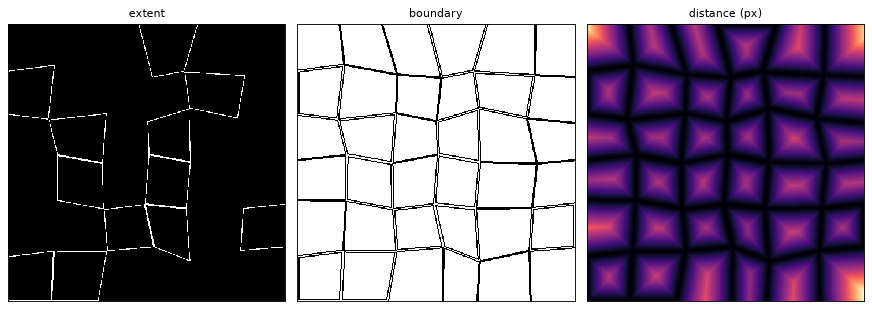

In [3]:
targets = field_targets(polygons, SHAPE)
print(f"{label(targets['extent'] > 0.5)[1]} blobs in the extent mask, from {len(polygons)} parcels")
panels = [("extent", targets["extent"], "gray_r"), ("boundary", targets["boundary"], "gray_r"),
          ("distance (px)", targets["distance"], "magma")]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, (title, image, cmap) in zip(axes, panels):
    ax.imshow(image, cmap=cmap, interpolation="nearest")
    ax.set(title=title, xticks=[], yticks=[])
fig.tight_layout()

## The model

Fields use the plain instance heads, with no corner or wall heads. Those lost to simple outlines on
Fields of The World in
[E046](https://github.com/DPIRD-DMA/ManySeg/tree/main/experiments/E046_ftw_trained), because
real field edges are often curved. We build the model only to check its output shapes.

In [4]:
model = create_model(backbone="resnet18", pretrained=False, in_channels=13,
                     heads=instance_heads()).eval()
with torch.no_grad():
    out = model(torch.rand(1, 13, 128, 128))
print({head: tuple(v.shape) for head, v in out.items()})

# A trained model's stitched scene would go here, with sigmoids on the two logit heads:
# fields = {k: (v if k == "distance" else v.sigmoid())[0].numpy() for k, v in out.items()}
fields = {k: targets[k] for k in ("extent", "boundary", "distance")}

{'extent': (1, 1, 128, 128), 'boundary': (1, 1, 128, 128), 'distance': (1, 1, 128, 128)}


## Decode block by block

This small scene uses 160 px blocks with a 32 px halo. Block edges fall close to field edges, and
the jitter pushes some fields across them. The result should match decoding the whole scene in one
go.

36 fields from 36 parcels; same as decoding in one go: True
IoU with the input parcels: median 0.988, min 0.981


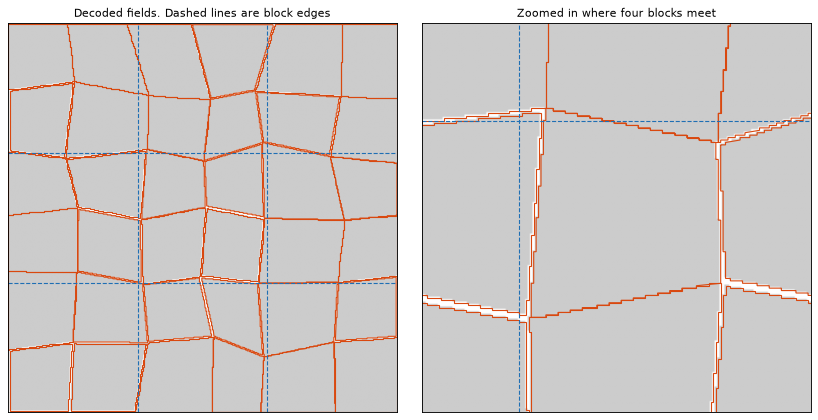

In [5]:
scene = Scene(*SHAPE, transform=TRANSFORM, crs=CRS)
decoder = block_decoder("fields")
records = decode_scene(fields, decoder, block=160, halo=32, scene=scene)
whole = decode_scene(fields, decoder, scene=scene)
same = len(records) == len(whole) and all(
    shapely.equals_exact(a["geometry"], b["geometry"], 0) for a, b in zip(records, whole))
print(f"{len(records)} fields from {len(parcels)} parcels; same as decoding in one go: {same}")


def best_iou(polys, truth):
    """For each true polygon, its IoU with the polygon that overlaps it best."""
    return [max((p.intersection(t).area / p.union(t).area for p in polys), default=0)
            for t in truth]


def draw(ax, polys, colour="#d9480f", lw=1.0):
    for p in polys:
        ax.add_patch(PolygonPatch(np.asarray(p.exterior.coords), fill=False, ec=colour, lw=lw))


decoded = [r["geometry"] for r in records]  # in pixels until written to a file
ious = best_iou(decoded, polygons)
print(f"IoU with the input parcels: median {np.median(ious):.3f}, min {min(ious):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 5.2))
for ax in axes:
    ax.imshow(fields["extent"], cmap="gray_r", vmin=0, vmax=5)
    draw(ax, decoded)
    for edge in (160, 320):
        ax.axhline(edge, c="#1f6fb4", ls="--", lw=1)
        ax.axvline(edge, c="#1f6fb4", ls="--", lw=1)
    ax.set(xticks=[], yticks=[])
axes[0].set_title("Decoded fields. Dashed lines are block edges")
axes[1].set(xlim=(120, 280), ylim=(280, 120), title="Zoomed in where four blocks meet")
fig.tight_layout()

## What keeps fields apart?

The decoder has two ways to separate neighbours. A boundary pixel above the threshold cuts them
apart, and each sharp distance peak starts its own field. So we weaken both and watch the count.
Blur and a little smooth noise make this a rough stand-in for a weak model, so read the trend and
not the scores. A count below 36 means fields have merged.

decoder thresholds: boundary 0.3, distance seed 3.0 px


boundary strength 0.0, distance blur 0.0: 36 fields


boundary strength 0.45, distance blur 4.0: 36 fields


boundary strength 0.25, distance blur 0.0: 36 fields


boundary strength 0.25, distance blur 4.0: 15 fields


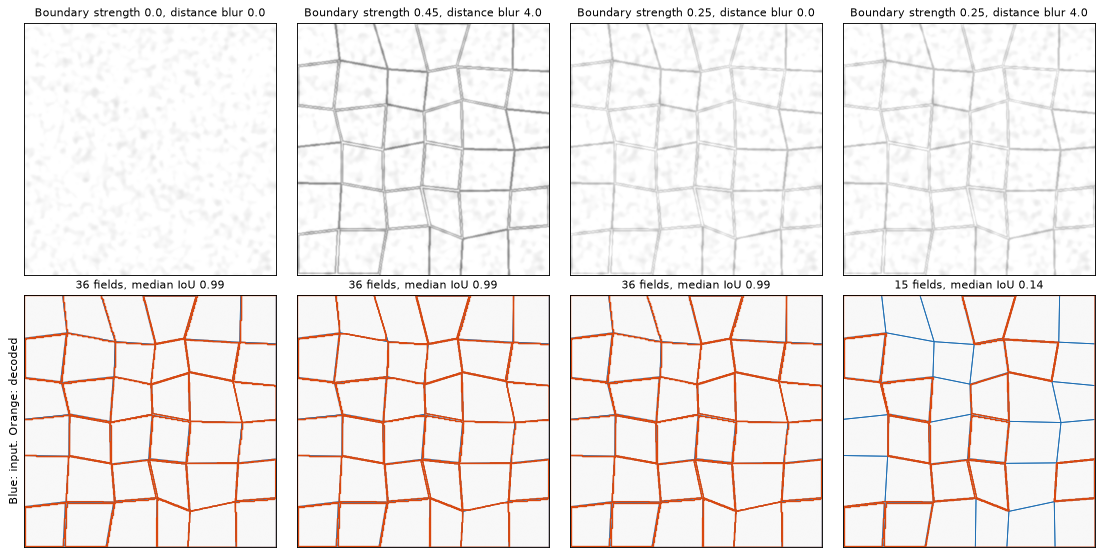

In [6]:
print(f"decoder thresholds: boundary {decoder.boundary_threshold}, "
      f"distance seed {decoder.seed_threshold} px")


def damage(fields, strength, blur, distance_blur, noise=0.03, seed=0):
    rng = np.random.default_rng(seed)
    out = dict(fields)
    grain = gaussian_filter(rng.normal(size=SHAPE).astype(np.float32), 4)
    boundary = gaussian_filter(fields["boundary"].astype(np.float32), blur) * strength
    out["boundary"] = np.clip(boundary + noise * grain / grain.std(), 0, 1)
    out["distance"] = gaussian_filter(fields["distance"].astype(np.float32), distance_blur)
    return out


levels = [(0.0, 0.0, 0.0), (0.45, 1.0, 4.0), (0.25, 1.0, 0.0), (0.25, 1.0, 4.0)]
fig, axes = plt.subplots(2, len(levels), figsize=(14, 7))
for column, (strength, blur, distance_blur) in zip(axes.T, levels):
    damaged = damage(fields, strength, blur, distance_blur)
    polys = [r["geometry"] for r in decode_scene(damaged, decoder, block=160, halo=32, scene=scene)]
    column[0].imshow(damaged["boundary"], cmap="gray_r", vmin=0, vmax=1)
    column[0].set_title(f"Boundary strength {strength}, distance blur {distance_blur}")
    column[1].imshow(np.full(SHAPE, 0.97), cmap="gray", vmin=0, vmax=1)
    draw(column[1], polygons, "#1f6fb4", 0.8)
    draw(column[1], polys, "#d9480f", 1.2)
    iou = np.median(best_iou(polys, polygons))
    column[1].set_title(f"{len(polys)} fields, median IoU {iou:.2f}")
    print(f"boundary strength {strength}, distance blur {distance_blur}: {len(polys)} fields")
for ax in axes.flat:
    ax.set(xticks=[], yticks=[])
axes[1, 0].set_ylabel("Blue: input. Orange: decoded")
fig.tight_layout()

Either signal can do the job alone. With no boundary at all, sharp distance peaks still separate
every field, and a boundary above the threshold copes with blurred distance. Fields only merge once
both are weak, which is why this model trains all three heads.

## Write GeoJSON

The records know the scene's transform and CRS, so the file comes out in world coordinates.

In [7]:
with TemporaryDirectory() as tmp:
    path = records.write(Path(tmp) / "fields.geojson")
    collection = json.loads(Path(path).read_text())
hectares = sum(shapely.geometry.shape(f["geometry"]).area for f in collection["features"]) / 1e4
print(f"{len(collection['features'])} fields, {hectares:.0f} ha in total")
print("properties:", list(collection["features"][0]["properties"]))

36 fields, 2247 ha in total
properties: ['id', 'pixels', 'scene_edge']


## Where to go next

* Train the heads briefly with
  [`examples/instance_fields.py`](https://github.com/DPIRD-DMA/ManySeg/blob/main/examples/instance_fields.py).
* See the other vector outputs: [footprints](03_vector_footprints.ipynb),
  [roads](05_vector_roads.ipynb), [roofs](06_vector_roofs.ipynb) and
  [points](07_vector_points.ipynb).